# 01 — Data Audit & Exploration: Barça Possession Challenge

**Tujuan:** memahami data aktual sebelum menetapkan radius, duration penalty, confidence, atau trigger tactical video. Notebook ini **bukan model possession** dan **tidak melakukan tuning ground truth publik**.

**Pertanyaan yang dijawab:**
1. Apa saja file yang tersedia dan apakah timeline-nya konsisten dengan `games.py`?
2. Seperti apa kolom ATD, metadata tim, cakupan pemain, missing ball, dan panjang gap?
3. Bagaimana distribusi jarak pemain–bola (dalam meter), kecepatan bola, dan anomali geraknya?
4. Kapan kedua tim sama-sama memiliki kandidat terdekat (*ambiguity proxy*)?
5. Apa cakupan Smart Tagging, kategori, nilai `Team`/`Type`, durasi, overlap, dan konteks set piece?
6. Bagaimana kualitas homography, dan dapatkah posisi tracking diproyeksikan ke frame video?
7. Analisis deskriptif apa yang relevan untuk desain modul live/dead, team-control, temporal buffering, dan video quality gate?

**Aturan:** tidak melabeli/koreksi frame pertandingan secara manual; tidak memakai ground truth publik sebagai train/validation/tuning; tidak menulis ekspor raw/derived frame-level; jangan unggah data kompetisi ke layanan pihak ketiga. Grafik/video di sini hanya untuk audit dan debugging visual, **bukan** menghasilkan label manusia.

**Struktur yang diasumsikan:**
```text
repo/
├── games.py
├── data/
│   └── tactical/
│       ├── BAR-ATH_tactical_atd.xml
│       ├── BAR-ATH_tactical_atd.txt
│       ├── BAR-ATH_tactical_smart_tagging.xml
│       ├── BAR-ATH_tactical_homography.csv
│       └── BAR-ATH_tactical.mp4
└── notebooks/
    └── 01_data_audit.ipynb
```

Dependensi: `pip install numpy pandas matplotlib kloppy opencv-python` (OpenCV opsional untuk sel video). Jalankan notebook dari `notebooks/` atau direktori lain; kode mencari `games.py` dari parent direktori kerja. Jika dataset berada di tempat lain gunakan environment `MTAH_DATA_DIR` **sebelum** membuka kernel.

In [17]:
from pathlib import Path
import os, sys, math, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Find actual repository root, independent of Jupyter launch directory.
CWD = Path.cwd().resolve()
ROOT_CANDIDATES = [CWD, *CWD.parents]
ROOT = next((p for p in ROOT_CANDIDATES if (p / "games.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("games.py tidak ditemukan. Simpan notebook dalam repo/notebooks/ atau jalankan dari repo.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import games
GAME = games.GAME
FPS = games.GAMES[GAME]["fps"]
N_FRAMES = games.source_frames("tactical", GAME)
PITCH_LENGTH, PITCH_WIDTH = games.GAMES[GAME]["pitch"]
HALF_BLOCKS = games.half_video_blocks(GAME)
PATHS = {k: Path(v) for k, v in games.asset_paths(GAME, source="tactical").items()}

print("Repository:", ROOT)
print("Data dir:", games.DATA_DIR)
print("Game:", GAME, "| FPS:", FPS, "| expected tactical frames:", N_FRAMES)
print("Half blocks (inclusive):", HALF_BLOCKS)
print("IdFrame offsets by half:", games.GAMES[GAME]["offsets"])
print("Pitch (m):", (PITCH_LENGTH, PITCH_WIDTH))

Repository: C:\Users\HP 840\Documents\Hizkia ITS\Lomba\MBG\more-than-a-hack-mbg
Data dir: C:\Users\HP 840\Documents\Hizkia ITS\Lomba\MBG\more-than-a-hack-mbg\data
Game: BAR-ATH | FPS: 25 | expected tactical frames: 199319
Half blocks (inclusive): [(1, 11185, 90651), (2, 110808, 190197)]
IdFrame offsets by half: {1: 1702057, 2: 1702058}
Pitch (m): (105.3, 68.0)


## 1 — Inventaris aset dan kontrak timeline

`games.asset_paths()` hanya membentuk lokasi file; `games.require()` benar-benar memeriksa keberadaan. **Tidak perlu broadcast**. Jika ada file belum tersedia, sel berikut melaporkannya tanpa membuat data dummy.

**Perhatian alignment:** pada `games.py`, `IdFrame` mentah pemetaan per babak memakai `id_to_video()`/`video_to_id()`. Sementara DataFrame `kloppy` dapat menampilkan `frame_id` berurutan 1..N, dengan konversi `video_frame=frame_id-1` **hanya jika terverifikasi**. Jangan mencampur kedua jenis counter.

In [18]:
inventory = pd.DataFrame([
    {"asset": name, "exists": p.is_file(), "size_MB": round(p.stat().st_size/1e6, 2) if p.is_file() else np.nan,
     "relative_path": str(p.relative_to(ROOT)) if p.is_relative_to(ROOT) else str(p)}
    for name, p in PATHS.items()
])
display(inventory)
required = ("atd_meta", "atd_raw", "smart_tagging", "homography")
missing = [k for k in required if not PATHS[k].is_file()]
if missing:
    print("BELUM TERSEDIA:", missing)
    print("Taruh file sesuai games.asset_paths(), lalu rerun notebook dari awal.")
else:
    print("Semua data tabular utama tersedia.")

# These boundary checks require no match assets.
for half, first, last in HALF_BLOCKS:
    assert games.half_of_video_frame(GAME, first) == half
    assert games.id_to_video(GAME, games.video_to_id(GAME, first)) == first
    assert games.id_to_video(GAME, games.video_to_id(GAME, last)) == last
print("Check per-half IdFrame ↔ video_frame: OK")

,asset,exists,size_MB,relative_path
0,video,True,5222.31,data\tactical\BAR-ATH_tactical.mp4
1,atd_meta,True,0.06,data\tactical\BAR-ATH_tactical_atd.xml
2,atd_raw,True,195.71,data\tactical\BAR-ATH_tactical_atd.txt
3,homography,True,23.19,data\tactical\BAR-ATH_tactical_homography.csv
4,smart_tagging,True,0.26,data\tactical\BAR-ATH_tactical_smart_tagging.xml


Semua data tabular utama tersedia.
Check per-half IdFrame ↔ video_frame: OK


## 2 — Muat ATD tactical dan inspeksi skema

Memakai parser yang disebut pada `DATA.md`: `kloppy.metrica.load_tracking_epts`. Karena satu pertandingan cukup besar, `to_df()` mungkin memerlukan memori beberapa ratus MB. Tidak menyimpan DataFrame ke disk. **Nama kolom tim dan ID pemain dapat bervariasi**: kita inspeksi dulu, bukan mengasumsikan `Track 1` = pemain tertentu.

In [19]:
try:
    from kloppy import metrica, sportscode
except ImportError as exc:
    raise ImportError("Install parser dengan: %pip install kloppy") from exc

# One clear failure if bundle hasn't been mounted.
games.require(required, game=GAME, source="tactical")

dataset = metrica.load_tracking_epts(
    meta_data=str(PATHS["atd_meta"]),
    raw_data=str(PATHS["atd_raw"]),
)
atd = dataset.to_df()
print("ATD shape:", atd.shape)
print("First columns:", atd.columns[:35].tolist())
print("Last columns:", atd.columns[-15:].tolist())
display(atd.head(3))
print("Column dtype summary:")
display(atd.dtypes.astype(str).value_counts().rename_axis("dtype").to_frame("count"))

ATD shape: (199319, 193)
First columns: ['period_id', 'timestamp', 'frame_id', 'ball_state', 'ball_owning_team_id', 'ball_x', 'ball_y', 'ball_z', 'ball_speed', '1_x', '1_y', '1_d', '1_s', '2_x', '2_y', '2_d', '2_s', '3_x', '3_y', '3_d', '3_s', '4_x', '4_y', '4_d', '4_s', '5_x', '5_y', '5_d', '5_s', '6_x', '6_y', '6_d', '6_s', '7_x', '7_y']
Last columns: ['43_y', '43_d', '43_s', '44_x', '44_y', '44_d', '44_s', '45_x', '45_y', '45_d', '45_s', '46_x', '46_y', '46_d', '46_s']


,period_id,timestamp,frame_id,ball_state,ball_owning_team_id,ball_x,ball_y,ball_z,ball_speed,1_x,...,44_d,44_s,45_x,45_y,45_d,45_s,46_x,46_y,46_d,46_s
0,1,0 days 00:00:00.040000,1,None,None,NaN,NaN,None,None,0.33411,...,None,NaN,NaN,NaN,None,NaN,0.06057,0.39965,None,NaN
1,1,0 days 00:00:00.080000,2,None,None,NaN,NaN,None,None,0.33404,...,None,NaN,NaN,NaN,None,NaN,0.06057,0.39965,None,NaN
2,1,0 days 00:00:00.120000,3,None,None,NaN,NaN,None,None,0.33396,...,None,NaN,NaN,NaN,None,NaN,0.06057,0.39965,None,NaN


Column dtype summary:


,count
dtype,
float64,140
object,50
int64,2
timedelta64[ns],1


In [20]:
# Validate frame_id interpretation; do not silently apply games.py's raw IdFrame offsets.
assert "frame_id" in atd.columns, "Expected 'frame_id' column absent; inspect parser/schema."
fid = pd.to_numeric(atd["frame_id"], errors="coerce")
print("ATD frame_id range:", fid.min(), fid.max(), "unique:", fid.nunique())
print("First 5 frame_id:", fid.head().tolist())
print("Last 5 frame_id:", fid.tail().tolist())

if len(atd) == N_FRAMES and np.array_equal(fid.to_numpy(), np.arange(1, N_FRAMES+1)):
    atd["video_frame"] = (fid - 1).astype(np.int32)
    print("Alignment: verified kloppy 1-based consecutive frame_id -> video_frame=frame_id-1")
else:
    # Fails loudly rather than accidentally corrupting downstream analysis.
    raise ValueError(
        "ATD frame_id bukan 1..N yang kontigu. Periksa apakah berisi raw IdFrame "
        "gunakan games.id_to_video() per babak jika benar raw IdFrame. Jangan lanjut dengan offset tebakan."
    )

# Report different spaces without claiming they're interchangeable.
print("Raw per-half IdFrame range from games.py:", games.halves(GAME))
print("Video half blocks:", HALF_BLOCKS)

ATD frame_id range: 1 199319 unique: 199319
First 5 frame_id: [1, 2, 3, 4, 5]
Last 5 frame_id: [199315, 199316, 199317, 199318, 199319]
Alignment: verified kloppy 1-based consecutive frame_id -> video_frame=frame_id-1
Raw per-half IdFrame range from games.py: [(1, 1713242, 1792708), (2, 1812866, 1892255)]
Video half blocks: [(1, 11185, 90651), (2, 110808, 190197)]


## 3 — Kelengkapan pemain dan bola

Fokus audit: proporsi `NaN`, jumlah slot pemain yang hadir per frame, dan kemungkinan duplikasi/identity switch. Kehadiran pemain ditentukan oleh pasangan `(x,y)` yang valid; tidak menyamakan track slot dengan nomor punggung.

Player track slots: 46 ['1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12'] ... ['41', '42', '43', '44', '45', '46']


,region,frames,ball_present_%,players_mean,players_p05,players_p95,over_22_frames
0,Full video,199319,56.94,18.98,7.0,22.0,7102
1,Graded halves,158857,59.31,20.49,14.0,22.0,3749
2,Half 1,79467,59.35,20.12,11.0,22.0,695
3,Half 2,79390,59.27,20.85,17.0,22.0,3054


Ball present with x/y separately: 113488 113488
Player count summary:


count    158857.000000
mean         20.487420
std           3.255342
min           1.000000
5%           14.000000
25%          21.000000
50%          22.000000
75%          22.000000
95%          22.000000
max          25.000000
dtype: float64

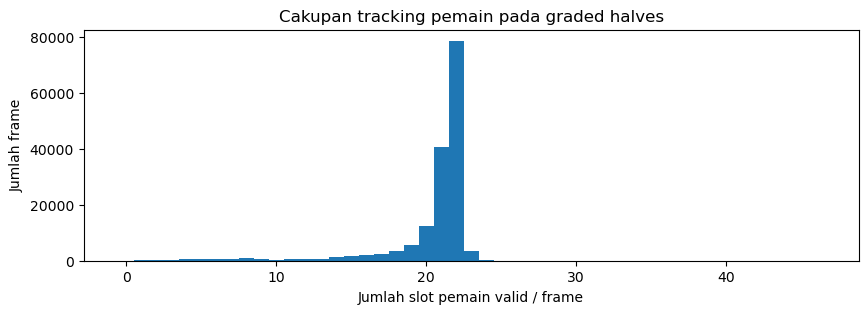

In [21]:
slot_pattern = re.compile(r"^(\d+)_(x|y|s)$")
slot_cols = {}
for col in atd.columns:
    match = slot_pattern.match(str(col))
    if match:
        slot_cols.setdefault(match.group(1), {})[match.group(2)] = col
slots = sorted([slot for slot, cs in slot_cols.items() if "x" in cs and "y" in cs], key=int)
print("Player track slots:", len(slots), slots[:12], "...", slots[-6:])
assert slots, "Tidak ditemukan pasangan kolom x/y track slot; periksa output kloppy."
assert {"ball_x", "ball_y"}.issubset(atd.columns), "Kolom ball_x/ball_y tidak ditemukan."

ball_x = pd.to_numeric(atd["ball_x"], errors="coerce").to_numpy(dtype=float)
ball_y = pd.to_numeric(atd["ball_y"], errors="coerce").to_numpy(dtype=float)
ball_valid = np.isfinite(ball_x) & np.isfinite(ball_y)
px = atd[[slot_cols[s]["x"] for s in slots]].apply(pd.to_numeric, errors="coerce").to_numpy(dtype=float)
py = atd[[slot_cols[s]["y"] for s in slots]].apply(pd.to_numeric, errors="coerce").to_numpy(dtype=float)
player_valid = np.isfinite(px) & np.isfinite(py)
player_count = player_valid.sum(axis=1)

grading = np.zeros(N_FRAMES, dtype=bool)
half_indicator = np.zeros(N_FRAMES, dtype=np.int8)
for half, start, stop in HALF_BLOCKS:
    grading[start:stop+1] = True
    half_indicator[start:stop+1] = half

summary = pd.DataFrame([
    {"region": region, "frames": int(mask.sum()),
     "ball_present_%": round(100*ball_valid[mask].mean(), 2),
     "players_mean": round(player_count[mask].mean(), 2),
     "players_p05": float(np.quantile(player_count[mask], .05)),
     "players_p95": float(np.quantile(player_count[mask], .95)),
     "over_22_frames": int((player_count[mask]>22).sum())}
    for region, mask in [("Full video", np.ones(N_FRAMES,bool)), ("Graded halves", grading),
                         ("Half 1",half_indicator==1),("Half 2",half_indicator==2)]
])
display(summary)
print("Ball present with x/y separately:", np.isfinite(ball_x).sum(), np.isfinite(ball_y).sum())
print("Player count summary:")
display(pd.Series(player_count[grading]).describe(percentiles=[.05,.25,.5,.75,.95]))

fig,ax=plt.subplots(figsize=(10,3))
ax.hist(player_count[grading],bins=np.arange(0,48)-.5)
ax.set(xlabel="Jumlah slot pemain valid / frame",ylabel="Jumlah frame",title="Cakupan tracking pemain pada graded halves")
plt.show()

## 4 — Missing ball: durasi dan konteks gap

Hitung **run panjang NaN** per babak secara terpisah agar gap tidak melintasi halftime. Tampilkan distribusi dalam frame/detik; kategori 5, 10, 25, dan 50 frame hanya sebagai referensi deskriptif, **bukan threshold terpilih**.

Jumlah missing-ball gaps: 150


,length_frames,seconds
count,150.000000,150.000000
mean,430.953333,17.238133
std,596.723237,23.868929
min,1.000000,0.040000
25%,152.250000,6.090000
50%,268.000000,10.720000
75%,526.500000,21.060000
90%,845.300000,33.812000
95%,1269.900000,50.796000
99%,2618.790000,104.751600


Gap length distribution:


,gaps
length_frames,
"(-0.001, 5.0]",14
"(5.0, 10.0]",1
"(10.0, 25.0]",2
"(25.0, 50.0]",0
"(50.0, 125.0]",1
"(125.0, inf]",132


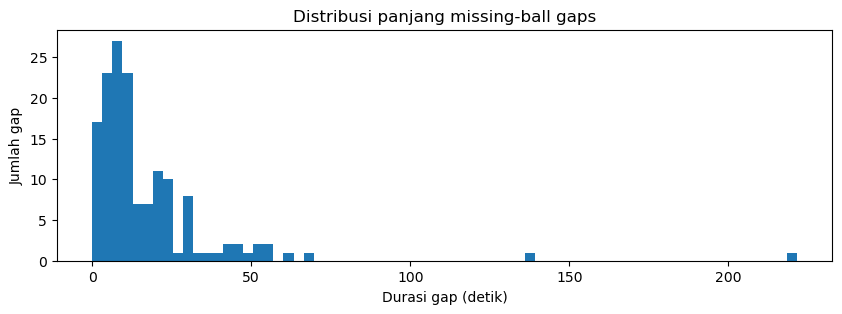

In [22]:
def runs_of_true(mask, offset=0):
    mask = np.asarray(mask, dtype=bool)
    switches = np.diff(np.r_[False, mask, False].astype(np.int8))
    starts = np.flatnonzero(switches == 1)
    ends = np.flatnonzero(switches == -1) - 1
    return pd.DataFrame({"start_frame": starts+offset, "end_frame": ends+offset,
                         "length_frames": ends-starts+1})

missing_segments=[]
for half, start, end in HALF_BLOCKS:
    gaps=runs_of_true(~ball_valid[start:end+1],start)
    gaps["half"]=half
    missing_segments.append(gaps)
missing_gaps=pd.concat(missing_segments, ignore_index=True)
missing_gaps["seconds"]=missing_gaps["length_frames"]/FPS
print("Jumlah missing-ball gaps:", len(missing_gaps))
display(missing_gaps[["length_frames","seconds"]].describe(percentiles=[.25,.5,.75,.9,.95,.99]))
print("Gap length distribution:")
display(pd.cut(missing_gaps.length_frames,[0,5,10,25,50,125,np.inf],include_lowest=True).value_counts().sort_index().to_frame("gaps"))

fig,ax=plt.subplots(figsize=(10,3))
ax.hist(missing_gaps["seconds"], bins=70)
ax.set(xlabel="Durasi gap (detik)",ylabel="Jumlah gap",title="Distribusi panjang missing-ball gaps")
plt.show()
# No export or user-specific manual frame correction: the table is purely diagnostic.

## 5 — Distribusi jarak dan gerak bola

Normalisasi `(x,y)` ATD menggunakan ukuran lapangan dari `games.GAMES[GAME]['pitch']`. Jarak terdekat adalah **bukti geometris**, bukan label possession. Kecepatan bola turunan hanya dihitung pada dua frame berturutan yang sama-sama memiliki observasi valid; tidak melakukan interpolasi lintas gap.

Nearest player-ball distance (m), observed frames only:


count    94214.000000
mean         3.110105
std          3.863417
min          0.001720
1%           0.098019
5%           0.273440
10%          0.440049
25%          0.891701
50%          1.913903
75%          4.060546
90%          7.021994
95%          9.559246
99%         16.353887
max         86.904342
dtype: float64

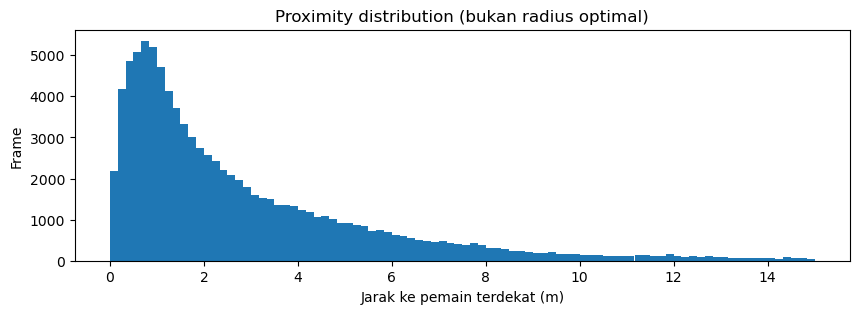

Observed 2D ball displacement speed (m/s):


count    94065.000000
mean         6.676758
std          5.965039
min          0.000000
50%          5.081759
90%         14.309995
95%         17.351455
99%         24.603603
max        109.597880
dtype: float64

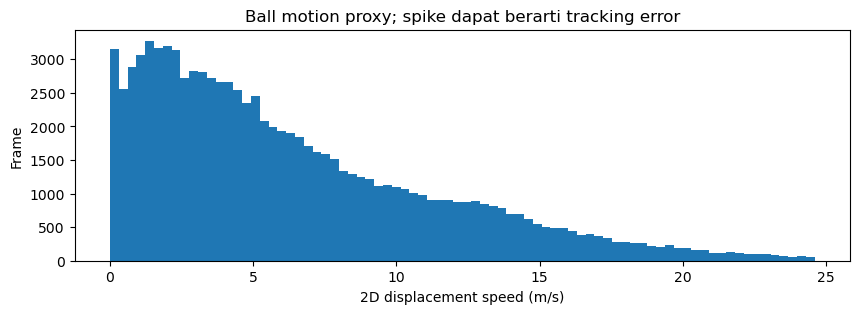

In [23]:
# float32 distances to reduce memory; ignores invalid observations.
dx = (px - ball_x[:,None]) * PITCH_LENGTH
dy = (py - ball_y[:,None]) * PITCH_WIDTH
distance_m = np.hypot(dx,dy)
distance_m[~player_valid | ~ball_valid[:,None]] = np.nan
nearest_distance = np.full(N_FRAMES,np.nan)
with np.errstate(all="ignore"):
    has_candidate = np.isfinite(distance_m).any(axis=1)
    nearest_distance[has_candidate]=np.nanmin(distance_m[has_candidate],axis=1)
nearest_slot = np.full(N_FRAMES,-1,dtype=int)
nearest_slot[has_candidate] = np.nanargmin(distance_m[has_candidate],axis=1)

good_dist = nearest_distance[grading & np.isfinite(nearest_distance)]
print("Nearest player-ball distance (m), observed frames only:")
display(pd.Series(good_dist).describe(percentiles=[.01,.05,.1,.25,.5,.75,.9,.95,.99]))
fig,ax=plt.subplots(figsize=(10,3))
ax.hist(good_dist, bins=90, range=(0,min(15,max(5,np.quantile(good_dist,.99)))))
ax.set(xlabel="Jarak ke pemain terdekat (m)",ylabel="Frame",title="Proximity distribution (bukan radius optimal)")
plt.show()

# Consecutive-frame 2D speed proxy, NOT the ball's 3D speed.
step_m=np.hypot(np.diff(ball_x)*PITCH_LENGTH,np.diff(ball_y)*PITCH_WIDTH)
step_ok=ball_valid[1:] & ball_valid[:-1] & (half_indicator[1:]==half_indicator[:-1]) & (half_indicator[1:]!=0)
ball_speed_2d=np.full(N_FRAMES,np.nan)
ball_speed_2d[1:][step_ok]=step_m[step_ok]*FPS
spd=ball_speed_2d[np.isfinite(ball_speed_2d)]
print("Observed 2D ball displacement speed (m/s):")
display(pd.Series(spd).describe(percentiles=[.5,.9,.95,.99]))
fig,ax=plt.subplots(figsize=(10,3))
ax.hist(spd,bins=80,range=(0,min(50,max(5,np.quantile(spd,.99)))))
ax.set(xlabel="2D displacement speed (m/s)",ylabel="Frame",title="Ball motion proxy; spike dapat berarti tracking error")
plt.show()

## 6 — Mapping tim otomatis dari metadata (jangan asumsikan slot)

Coba baca afiliasi tim melalui metadata `dataset.metadata.teams` dan ID pemain yang disediakan parser. Mapping ini **bukan** re-identification permanen: hanya mencoba memberi label afiliasi pada slot yang tercantum. Bila parser menyajikan ID lain atau tidak dapat diverifikasi, jangan memaksakan H/A; lanjutkan audit tanpa statistik kedua tim.

In [24]:
teams = list(getattr(dataset.metadata,"teams",[]) or [])
print("metadata.teams count:",len(teams))
for k,team in enumerate(teams):
    players=list(getattr(team,"players",[]) or [])
    print("TEAM",k,"name:",repr(getattr(team,"name",None)),"team_id:",repr(getattr(team,"team_id",None)),
          "n_players:",len(players),"sample IDs:",[(str(getattr(p,"player_id",None)),str(getattr(p,"name",None))) for p in players[:4]])

# Try several explicit ID string representations. Never infer team from nearest player alone.
slot_to_side={}
for team in teams:
    name=str(getattr(team,"name","") or "").lower()
    # Team-name identification is a contextual hypothesis based on official match metadata.
    if "barcelona" in name: side="H"
    elif "athletic" in name or "atletic" in name: side="A"
    else: continue
    for player in (getattr(team,"players",[]) or []):
        candidate_ids=[getattr(player,"player_id",None),getattr(player,"name",None)]
        for pid in candidate_ids:
            match=re.fullmatch(r"(?:track\s*)?(\d+)",str(pid or "").strip(),flags=re.IGNORECASE)
            if match and match.group(1) in slots:
                slot_to_side[match.group(1)]=side

print("Metadata-resolved slot affiliation:",len(slot_to_side),"of",len(slots))
print("Counts:",pd.Series(list(slot_to_side.values())).value_counts().to_dict())
if len(slot_to_side)<len(slots) or len(set(slot_to_side.values()))<2:
    print("WARNING: mapping incomplete/unverified. Team proximity below will be skipped unless metadata is reconciled programmatically.")

# Inspect metadata representations safely (small samples; do not dump full dataset).
for team in teams[:2]:
    if len(getattr(team,"players",[]) or [])>0:
        p=list(team.players)[0]
        print("Example player metadata:", repr(p)[:600])

metadata.teams count: 2
TEAM 0 name: 'Barcelona' team_id: 'MET_user_team_o4Hossvb8M' n_players: 24 sample IDs: [('1', 'Track 1'), ('2', 'Track 2'), ('3', 'Track 3'), ('4', 'Track 4')]
TEAM 1 name: 'Atletic Club' team_id: 'MET_user_team_x7C4FFX2HF' n_players: 22 sample IDs: [('25', 'Track 25'), ('26', 'Track 26'), ('27', 'Track 27'), ('28', 'Track 28')]
Metadata-resolved slot affiliation: 46 of 46
Counts: {'H': 24, 'A': 22}
Example player metadata: <Player name='Track 1' player_id='1'>
Example player metadata: <Player name='Track 25' player_id='25'>


Both-team-distance-available frames: 94030
Absolute H/A distance margin (metres):


count    94030.000000
mean         5.290473
std          5.725453
min          0.000015
5%           0.290344
25%          1.481007
50%          3.529415
75%          7.273543
95%         15.680154
max         57.137761
dtype: float64

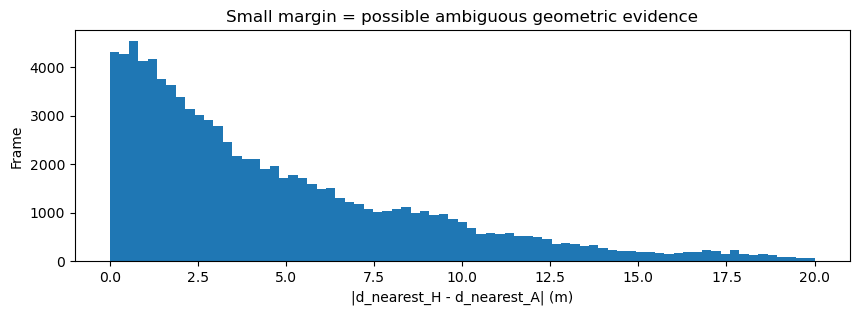

In [25]:
# Diagnostic margin is only valid if all slots have verified affiliation for both teams.
team_map_verified = (len(slot_to_side)==len(slots) and set(slot_to_side.values())=={"H","A"})
if team_map_verified:
    side_arr=np.array([slot_to_side[s] for s in slots])
    team_nearest={}
    for side in ("H","A"):
        subset=distance_m[:,side_arr==side]
        vals=np.full(N_FRAMES,np.nan)
        good=np.isfinite(subset).any(axis=1)
        vals[good]=np.nanmin(subset[good],axis=1)
        team_nearest[side]=vals
    h, a=team_nearest["H"],team_nearest["A"]
    both=grading & np.isfinite(h) & np.isfinite(a)
    margin=np.abs(h[both]-a[both])
    print("Both-team-distance-available frames:",int(both.sum()))
    print("Absolute H/A distance margin (metres):")
    display(pd.Series(margin).describe(percentiles=[.05,.25,.5,.75,.95]))
    fig,ax=plt.subplots(figsize=(10,3))
    ax.hist(margin,bins=75,range=(0,min(20,max(5,np.quantile(margin,.99)))))
    ax.set(xlabel="|d_nearest_H - d_nearest_A| (m)",ylabel="Frame",title="Small margin = possible ambiguous geometric evidence")
    plt.show()
else:
    print("SKIP: team proximity. Need verified slot→team mapping from kloppy metadata before calculating H/A distances.")

## 7 — Smart Tagging: schema, durasi, distribusi, overlap

`start`/`end` adalah detik dari awal tactical video. Pada `kloppy` biasanya kolom `timestamp`/`end_timestamp` berupa timedeltas. Nilai kode/kolom **case-sensitive** (`Team`, `Type` dan `SET PIECES`). Interval dipakai untuk audit konteks, **bukan** dijadikan possession ground truth.

In [26]:
events = sportscode.load(str(PATHS["smart_tagging"])).to_df()
print("Smart Tagging shape:", events.shape)
print("Columns:",events.columns.tolist())
display(events.head(5))
assert {"timestamp","end_timestamp","code"}.issubset(events.columns), "Smart Tagging schema unexpected. Inspect above."

# Accept Timedelta or numeric seconds, avoid treating numeric seconds as nanoseconds.
def to_seconds(series):
    if pd.api.types.is_timedelta64_dtype(series):
        return series.dt.total_seconds()
    if pd.api.types.is_numeric_dtype(series):
        return pd.to_numeric(series,errors="coerce").astype(float)
    return pd.to_timedelta(series, errors="coerce").dt.total_seconds()

events=events.copy()
events["start_sec"]=to_seconds(events["timestamp"])
events["end_sec"]=to_seconds(events["end_timestamp"])
events["start_frame"]=np.rint(events.start_sec*FPS).astype("Int64")
events["end_frame"]=np.rint(events.end_sec*FPS).astype("Int64")
events["duration_sec"]=(events.end_sec-events.start_sec)
print("Null/negative durations:",int(events.duration_sec.isna().sum()),int((events.duration_sec<0).sum()))
print("Out of timeline starts/ends:",int(((events.start_frame<0)|(events.end_frame>=N_FRAMES)).fillna(False).sum()))
print("Tag codes:")
display(events["code"].astype(str).value_counts().to_frame("instances"))
for key in ("Team","Half","Type"):
    if key in events.columns:
        print("Tag",key)
        display(events[key].astype(str).value_counts(dropna=False).head(30).to_frame("instances"))
print("Duration distribution (seconds):")
display(events.duration_sec.describe(percentiles=[.1,.25,.5,.75,.9,.95]))

Smart Tagging shape: (638, 11)
Columns: ['code_id', 'period_id', 'timestamp', 'end_timestamp', 'code', 'Team', 'Type', 'Half', 'Max Players in the box', 'Side', 'Direction of ball entry']


,code_id,period_id,timestamp,end_timestamp,code,Team,Type,Half,Max Players in the box,Side,Direction of ball entry
0,1,1,0 days 00:07:23.880000,0 days 00:07:28.880000,SET PIECES,N/A,Kick Off (Start),1st Half,None,None,None
1,2,1,0 days 00:33:05.240000,0 days 00:33:10.240000,SET PIECES,N/A,Kick Off (After Goal),1st Half,None,None,None
2,3,1,0 days 00:41:20.480000,0 days 00:41:25.480000,SET PIECES,N/A,Kick Off (After Goal),1st Half,None,None,None
3,4,1,0 days 00:50:18.280000,0 days 00:50:23.280000,SET PIECES,N/A,Kick Off (After Goal),1st Half,None,None,None
4,5,1,0 days 01:15:46.400000,0 days 01:15:51.400000,SET PIECES,N/A,Kick Off (Start),2nd Half,None,None,None


Null/negative durations: 0 0
Out of timeline starts/ends: 0
Tag codes:


,instances
code,
PLAYERS IN THE BOX,97
BALL IN FINAL THIRD,93
BALL IN THE BOX,72
PROGRESSION,66
DEFENDING IN MIDDLE THIRD,66
SET PIECES,59
CREATING CHANCES,30
DEFENDING IN DEFENSIVE THIRD,30
LONG BALL,29


Tag Team


,instances
Team,
Barcelona,314
Atletic Club,288
N/A,36


... (2 outputs left out)

Tag Type


,instances
Type,
None,579
Throw-in,26
Corner Kick,12
Goal Kick,10
Free Kick,5
Kick Off (After Goal),4
Kick Off (Start),2


Duration distribution (seconds):


count    638.000000
mean      25.686271
std       17.012556
min        5.000000
10%       12.600000
25%       16.840000
50%       22.820000
75%       30.000000
90%       35.096000
95%       49.694000
max      250.720000
Name: duration_sec, dtype: float64

Tag coverage (any active tag), graded halves: 82.27 %
Overlapping-tag frames: 92258
Tags per graded frame distribution:


,frames
0,28159
1,38440
2,25965
3,22279
4,13197
5,12602
6,9810
7,5743
8,1357
9,917


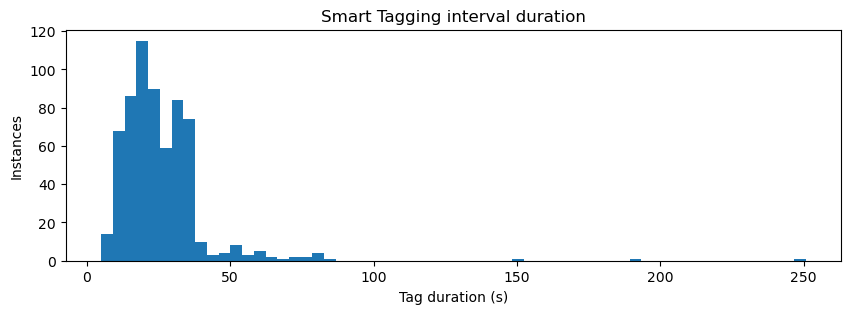

SET PIECES records: 59


,start_frame,end_frame,duration_sec,Team,Type,Half
0,11097,11222,5.0,N/A,Kick Off (Start),1st Half
1,49631,49756,5.0,N/A,Kick Off (After Goal),1st Half
2,62012,62137,5.0,N/A,Kick Off (After Goal),1st Half
3,75457,75582,5.0,N/A,Kick Off (After Goal),1st Half
4,113660,113785,5.0,N/A,Kick Off (Start),2nd Half
5,163000,163125,5.0,N/A,Kick Off (After Goal),2nd Half
413,130321,131196,35.0,Barcelona,Corner Kick,2nd Half
414,42614,43489,35.0,Atletic Club,Corner Kick,1st Half
415,36939,37814,35.0,Atletic Club,Corner Kick,1st Half
416,136426,137301,35.0,Atletic Club,Corner Kick,2nd Half


In [27]:
# Efficient frame-level coverage and overlap counts for interval tags.
# Define interval as [start_frame, end_frame) for exploration only.
# Endpoint convention is not guaranteed by docs: do NOT use these boundaries as labeled events.
cover_delta=np.zeros(N_FRAMES+1,dtype=np.int32)
for start,end in events[["start_frame","end_frame"]].dropna().itertuples(index=False,name=None):
    lo=max(0,min(N_FRAMES,int(start)))
    hi=max(0,min(N_FRAMES,int(end)))
    if hi>lo:
        cover_delta[lo]+=1
        cover_delta[hi]-=1
active_tag_count=np.cumsum(cover_delta[:-1])
print("Tag coverage (any active tag), graded halves:",round(active_tag_count[grading].astype(bool).mean()*100,2),"%")
print("Overlapping-tag frames:",int(((active_tag_count>1)&grading).sum()))
print("Tags per graded frame distribution:")
display(pd.Series(active_tag_count[grading]).value_counts().sort_index().head(20).to_frame("frames"))

fig,ax=plt.subplots(figsize=(10,3))
ax.hist(events.duration_sec.dropna(),bins=60)
ax.set(xlabel="Tag duration (s)",ylabel="Instances",title="Smart Tagging interval duration")
plt.show()

set_pieces=events.loc[events.code.astype(str).str.upper().eq("SET PIECES")].copy()
print("SET PIECES records:",len(set_pieces))
if len(set_pieces):
    cols=[c for c in ["start_frame","end_frame","duration_sec","Team","Type","Half"] if c in set_pieces]
    display(set_pieces[cols].head(12))

## 8 — Konteks tracking di sekitar SET PIECES (tanpa label dead-ball)

Tujuan: melihat apakah observasi (ball visibility, player count, speed proxy) berubah di sekitar **awal/akhir interval tagging**. Tidak menganggap tag sebagai waktu dead/live yang benar. Menggunakan jendela ±5 detik hanya untuk visualisasi; tidak mengoptimalkan parameter model.

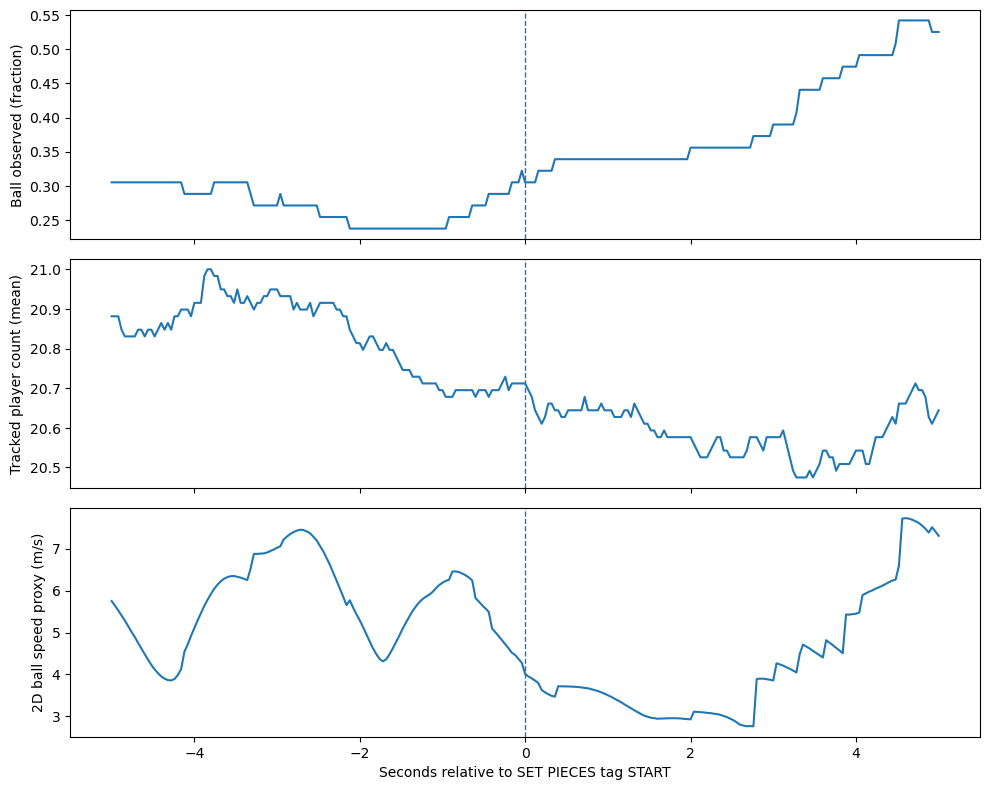

In [28]:
WINDOW = 5*FPS
anchors=np.asarray(set_pieces["start_frame"].dropna(),dtype=int)
anchors=anchors[(anchors>=0)&(anchors<N_FRAMES)]
relative=np.arange(-WINDOW,WINDOW+1)

def event_window_curve(values,anchors,relative):
    arr=np.asarray(values,dtype=float)
    samples=np.full((len(anchors),len(relative)),np.nan)
    for i,anchor in enumerate(anchors):
        ids=anchor+relative
        ok=(ids>=0)&(ids<len(arr))
        samples[i,ok]=arr[ids[ok]]
    valid_ct=np.isfinite(samples).sum(axis=0)
    return np.divide(np.nansum(samples,axis=0),valid_ct,out=np.full(len(relative),np.nan),where=valid_ct>0)

if len(anchors):
    fig,axs=plt.subplots(3,1,figsize=(10,8),sharex=True)
    for ax,v,title in zip(axs,[ball_valid.astype(float),player_count.astype(float),ball_speed_2d],
                          ["Ball observed (fraction)","Tracked player count (mean)","2D ball speed proxy (m/s)"]):
        ax.plot(relative/FPS,event_window_curve(v,anchors,relative))
        ax.axvline(0,ls="--",lw=1)
        ax.set_ylabel(title)
    axs[-1].set_xlabel("Seconds relative to SET PIECES tag START")
    plt.tight_layout();plt.show()
else:
    print("No SET PIECES events to inspect.")

## 9 — Homography quality audit

File matriks `h00`…`h22` + `valid` + `reprojection_error`. `valid=1` hanya berarti matriks tersedia, bukan proyeksi sempurna. Pemeriksaan di sini tidak membutuhkan video.

Homography: (199319, 12) first columns: ['frame', 'h00', 'h01', 'h02', 'h10', 'h11', 'h12', 'h20', 'h21', 'h22', 'reprojection_error', 'valid']


,frame,h00,h01,h02,h10,h11,h12,h20,h21,h22,reprojection_error,valid
0,0,1834.51428,-519.781433,45.983478,5.733814,162.882401,256.334229,-0.008851,-0.534427,1,0.589505,1
1,1,1834.55481,-519.716187,45.878456,5.647519,162.892273,256.363373,-0.008816,-0.534435,1,0.574035,1
2,2,1834.59546,-519.650940,45.773430,5.561231,162.902145,256.392517,-0.008781,-0.534442,1,0.558565,1


Valid value counts:


,frames
valid,
1,199319


Reprojection error, graded frames:


count    158857.000000
mean          0.296384
std           0.511894
min           0.062284
50%           0.230840
90%           0.307819
95%           0.356650
99%           4.295122
max           5.453117
Name: reprojection_error, dtype: float64

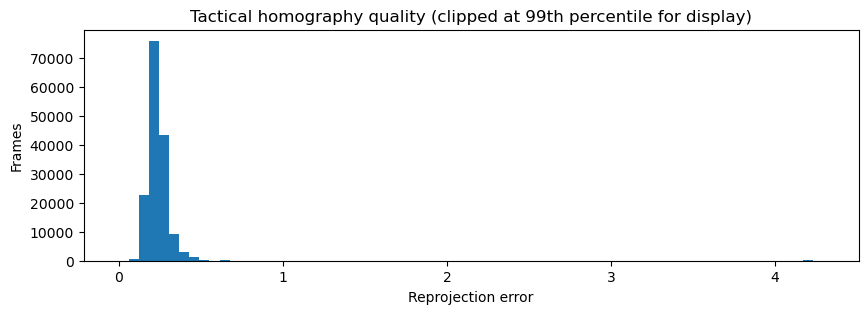

In [29]:
hom=pd.read_csv(PATHS["homography"])
print("Homography:",hom.shape,"first columns:",hom.columns.tolist())
display(hom.head(3))
H_COLS=[f"h{i}{j}" for i in range(3) for j in range(3)]
assert {"frame","valid","reprojection_error",*H_COLS}.issubset(hom.columns)
assert len(hom)==N_FRAMES,"Homography count differs from reference video"
assert np.array_equal(hom.frame.to_numpy(),np.arange(N_FRAMES)),"Homography frame alignment unexpected"
print("Valid value counts:")
display(hom.valid.value_counts(dropna=False).to_frame("frames"))
print("Reprojection error, graded frames:")
display(pd.to_numeric(hom.loc[grading,"reprojection_error"],errors="coerce").describe(percentiles=[.5,.9,.95,.99]))

fig,ax=plt.subplots(figsize=(10,3))
vals=pd.to_numeric(hom.loc[grading,"reprojection_error"],errors="coerce").dropna()
ax.hist(vals,bins=70,range=(0,max(1,np.quantile(vals,.99))))
ax.set(xlabel="Reprojection error",ylabel="Frames",title="Tactical homography quality (clipped at 99th percentile for display)")
plt.show()

## 10 — Tactical video + homography: inspeksi overlay opsional

**Tidak ada anotasi/koreksi manual.** Ambil frame deterministik (anchor kickoff dari `games.py`) dan tampilkan overlay lokasi bola/pemain hasil tracking. Gunakan untuk memeriksa orientasi proyeksi dan memahami error. Ini hanya visual diagnostik, bukan penentuan label. Sel ini **tidak membaca broadcast**.

Jika OpenCV atau video belum ada, sel akan melewati tanpa menggagalkan audit data tabular. Proyeksi bola udara ke bidang lapangan bisa meleset.

In [30]:
def project_normalized(H, x, y):
    uvw = H @ np.array([x,y,1.0],dtype=float)
    if not np.isfinite(uvw).all() or abs(uvw[2])<1e-10:
        return (np.nan,np.nan)
    return (uvw[0]/uvw[2],uvw[1]/uvw[2])

def show_tactical_overlay(video_frame):
    try:
        import cv2
    except ImportError:
        print("Install opencv-python untuk visualisasi video.")
        return
    if not PATHS["video"].is_file():
        print("Video belum ada:",PATHS["video"])
        return
    if video_frame<0 or video_frame>=N_FRAMES:
        print("Frame di luar range")
        return
    cap=cv2.VideoCapture(str(PATHS["video"]))
    try:
        cap.set(cv2.CAP_PROP_POS_FRAMES,int(video_frame))
        ok,frame=cap.read()
    finally:
        cap.release()
    if not ok:
        print("Tidak bisa decode frame",video_frame)
        return
    frame=cv2.cvtColor(frame,cv2.COLOR_BGR2RGB)
    row=hom.iloc[int(video_frame)]
    if not bool(row["valid"]):
        print("Invalid homography, showing unprojected frame.")
    else:
        H=row[H_COLS].to_numpy(dtype=float).reshape(3,3)
        # Draw with matplotlib so original image is never altered or exported.
    fig,ax=plt.subplots(figsize=(14,8))
    ax.imshow(frame)
    if bool(row["valid"]):
        for j in range(len(slots)):
            if player_valid[video_frame,j]:
                u,v=project_normalized(H,px[video_frame,j],py[video_frame,j])
                if np.isfinite([u,v]).all():
                    ax.plot(u,v,"o",ms=4,color="cyan",alpha=.75)
        if ball_valid[video_frame]:
            u,v=project_normalized(H,ball_x[video_frame],ball_y[video_frame])
            if np.isfinite([u,v]).all():
                ax.plot(u,v,"o",ms=10,mfc="none",mec="yellow",mew=2)
    ax.set(title=f"Tactical frame {video_frame} — tracking overlay (diagnostic)",xlim=(0,frame.shape[1]),ylim=(frame.shape[0],0))
    plt.show()

frame_anchor=games.anchor_video_frame(games.GAMES[GAME]["kickoff"])
print("Anchor frame:",frame_anchor)
show_tactical_overlay(frame_anchor)

Anchor frame: 11186
Install opencv-python untuk visualisasi video.


## 11 — Hipotesis desain, tindakan berikutnya, dan batas inferensi

**Apa yang bisa diputuskan dari audit ini:**
- Apakah frame dan parser konsisten? Jika tidak, perbaiki sebelum modeling.
- Seberapa sering dan selama berapa lama bola hilang? Bedakan gap singkat dan panjang lewat distribusi, bukan label.
- Berapa rentang jarak pemain-bola yang wajar? Gunakan sebagai rentang kandidat, **bukan** radius possession hasil tuning.
- Apakah metadata memungkinkan afiliasi tim yang konsisten? Jika tidak, prioritaskan parser/mapping yang benar.
- Seberapa informatif Smart Tagging soal restart dan seberapa sering tag overlap? Tetap jangan berasumsi SET PIECES = keseluruhan dead ball.
- Apakah homography cukup baik untuk overlay/crop? Kalau tidak, turunkan bobot atau jangan lakukan crop sempit.

**Hal yang tidak dapat dibuktikan dari notebook ini:** akurasi possession, threshold H/A/D optimal, waktu pergantian possession yang benar, atau apakah event tertentu pasti dead ball. Untuk itu diperlukan eksperimen yang sah pada game lain, simulasi, dan akhirnya evaluasi privat oleh penyelenggara.

**Eksperimen lanjut yang direkomendasikan:**
1. Definisikan *observation features* dan quality flags (missingness, speed spike, mapping tim).
2. Buat dead/live evidence berbasis kombinasi motion + set piece context (tanpa menyalin tag sebagai ground truth).
3. Bangun team control evidence, lalu bandingkan HMM/Viterbi/HSMM dengan baseline.
4. Uji synthetic frame sequences: deflection, interception pendek, stop/restart, missing near turnover.
5. Gunakan video secara selektif; quality gate hasil deteksi visual.

**Jangan simpan** raw frame-level CSV hasil audit ke repository publik. Jika perlu laporan agregat, cek persyaratan lisensi sebelum membagikannya.